[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/solutions/02_mlp_backprop_solutions.ipynb)

# Exercises 2 — Multilayer Perceptrons and Backpropagation

Fill in every cell marked `# YOUR CODE HERE` and answer the written questions.
The `assert` cells check your work: if a cell runs without an error, you are
probably on the right track.

We use the same conventions as the lecture: a mini-batch is a matrix with **one
example per row**, a layer's `forward(X)` caches what it needs, and `backward(dY)`
receives $\partial\mathcal L/\partial Y$, stores the gradients of the layer's own
parameters, and returns $\partial\mathcal L/\partial X$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles, load_digits
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(0)

The following helpers are given. `grad_check` compares the analytical gradients
produced by `backward` with central finite differences and returns the relative
error; `check_layer` does the same for a single layer with a random linear "loss"
$\mathcal L = \sum_{ij} G_{ij}Y_{ij}$, so that the upstream gradient is simply $G$.

In [2]:
class Module:
    def params(self):
        return []
    def grads(self):
        return []


class Sequential(Module):
    def __init__(self, *layers):
        self.layers = list(layers)
    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X
    def backward(self, dY):
        for layer in reversed(self.layers):
            dY = layer.backward(dY)
        return dY
    def params(self):
        return [p for l in self.layers for p in l.params()]
    def grads(self):
        return [g for l in self.layers for g in l.grads()]


class SoftmaxCrossEntropy:
    def forward(self, Z, y):
        Z = Z - Z.max(axis=1, keepdims=True)
        logP = Z - np.log(np.exp(Z).sum(axis=1, keepdims=True))
        self.P, self.y = np.exp(logP), y
        return -np.mean(logP[np.arange(len(y)), y])
    def backward(self):
        G = self.P.copy()
        G[np.arange(len(self.y)), self.y] -= 1
        return G / len(self.y)


def rel_error(a, b):
    return np.linalg.norm(a - b) / max(np.linalg.norm(a + b), 1e-12)


def check_layer(layer, X, h=1e-6, seed=0):
    """Relative errors of dX and of every parameter gradient of a single layer."""
    G = np.random.default_rng(seed).normal(size=layer.forward(X).shape)
    loss = lambda: np.sum(G * layer.forward(X))
    layer.forward(X)
    dX = layer.backward(G)
    analytic = [dX] + [g.copy() for g in layer.grads()]
    errors = []
    for arr, ana in zip([X] + layer.params(), analytic):
        num = np.zeros_like(arr)
        for i in np.ndindex(arr.shape):
            old = arr[i]
            arr[i] = old + h; Lp = loss()
            arr[i] = old - h; Lm = loss()
            arr[i] = old
            num[i] = (Lp - Lm) / (2 * h)
        errors.append(rel_error(num, ana))
    return errors


def grad_check(model, loss_fn, X, y, h=1e-6):
    loss_fn.forward(model.forward(X), y)
    model.backward(loss_fn.backward())
    analytic = np.concatenate([g.ravel() for g in model.grads()])
    numeric = []
    for p in model.params():
        for i in np.ndindex(p.shape):
            old = p[i]
            p[i] = old + h; Lp = loss_fn.forward(model.forward(X), y)
            p[i] = old - h; Lm = loss_fn.forward(model.forward(X), y)
            p[i] = old
            numeric.append((Lp - Lm) / (2 * h))
    return rel_error(np.array(numeric), analytic)

## Exercise 2.1 — The backward pass of a linear layer

Complete `Linear.backward`. Given the upstream gradient `dY` of shape `(N, n_out)`
it must

* write $\partial\mathcal L/\partial W$ into `self.dW` and $\partial\mathcal L/\partial \mathbf b$ into `self.db`
  (use `self.dW[...] = ...` so that the arrays returned by `grads()` are updated in place), and
* return $\partial\mathcal L/\partial X$, of shape `(N, n_in)`.

*Hint:* each gradient has the same shape as the quantity it belongs to.

In [3]:
class Linear(Module):
    def __init__(self, n_in, n_out, rng):
        self.W = rng.normal(0.0, np.sqrt(2.0 / n_in), size=(n_in, n_out))
        self.b = np.zeros(n_out)
        self.dW, self.db = np.zeros_like(self.W), np.zeros_like(self.b)

    def forward(self, X):
        self.X = X
        return X @ self.W + self.b

    def backward(self, dY):
        self.dW[...] = self.X.T @ dY
        self.db[...] = dY.sum(axis=0)
        return dY @ self.W.T

    def params(self):
        return [self.W, self.b]
    def grads(self):
        return [self.dW, self.db]

In [4]:
errs = check_layer(Linear(4, 3, np.random.default_rng(1)), rng.normal(size=(5, 4)))
print("relative errors (dX, dW, db):", ["%.1e" % e for e in errs])
assert all(e < 1e-7 for e in errs)
print("Linear OK")

relative errors (dX, dW, db): ['1.1e-10', '5.7e-11', '9.4e-11']
Linear OK


## Exercise 2.2 — Activation layers

Implement `forward` and `backward` for `ReLU`, `Sigmoid` and `Tanh`. Cache in
`forward` whatever `backward` needs. Express the derivatives of sigmoid and tanh
through their **outputs** (e.g. $\sigma' = \sigma(1-\sigma)$), so you do not have to
recompute any exponentials. The sigmoid must not overflow for large $|z|$
(see Exercise 1.1).

In [5]:
class ReLU(Module):
    def forward(self, X):
        self.mask = X > 0
        return X * self.mask
    def backward(self, dY):
        return dY * self.mask


class Sigmoid(Module):
    def forward(self, X):
        out = np.empty_like(X, dtype=float)
        pos = X >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-X[pos]))
        ez = np.exp(X[~pos])
        out[~pos] = ez / (1.0 + ez)
        self.S = out
        return out
    def backward(self, dY):
        return dY * self.S * (1 - self.S)


class Tanh(Module):
    def forward(self, X):
        self.H = np.tanh(X)
        return self.H
    def backward(self, dY):
        return dY * (1 - self.H ** 2)

In [6]:
Xa = rng.normal(size=(6, 5)) * 2
for layer in (ReLU(), Sigmoid(), Tanh()):
    err = check_layer(layer, Xa.copy())[0]
    print(f"{type(layer).__name__:8s} dX relative error {err:.1e}")
    assert err < 1e-7
with np.errstate(over="raise"):
    s = Sigmoid().forward(np.array([[-1000.0, 0.0, 1000.0]]))
assert np.allclose(s, [[0.0, 0.5, 1.0]])
assert np.allclose(ReLU().forward(np.array([[-2.0, 0.0, 3.0]])), [[0.0, 0.0, 3.0]])
print("activations OK")

ReLU     dX relative error 1.1e-10
Sigmoid  dX relative error 3.4e-10
Tanh     dX relative error 9.2e-11
activations OK


Now check a whole network built from your layers. Because all components are
composed through `Sequential`, a correct gradient for every layer automatically
gives a correct gradient for the network — this is the modularity that makes
backpropagation practical.

In [7]:
r = np.random.default_rng(2)
net = Sequential(Linear(4, 6, r), Tanh(), Linear(6, 5, r), Sigmoid(), Linear(5, 3, r))
Xn, yn = r.normal(size=(7, 4)), r.integers(0, 3, size=7)
err = grad_check(net, SoftmaxCrossEntropy(), Xn, yn)
print(f"full network relative error {err:.1e}")
assert err < 1e-7

full network relative error 7.6e-10


## Exercise 2.3 — Backpropagation by hand (pen and paper)

Consider the scalar computation

$$ a = w_1 x, \qquad h = \tanh(a), \qquad z = w_2 h + w_3 x, \qquad \mathcal L = \tfrac12 (z - y)^2 . $$

Note that $x$ reaches $z$ along **two** paths.

1. Draw the computational graph.
2. Write down the backward pass, i.e. expressions for $\bar z, \bar h, \bar a, \bar w_1, \bar w_2, \bar w_3$
   and $\bar x$ (where $\bar v = \partial\mathcal L/\partial v$).
3. Evaluate them numerically for $x = 1,\ y = 0,\ w_1 = 0.5,\ w_2 = -1,\ w_3 = 2$ and enter
   the results as variables `w1_bar` and `x_bar` in the code cell below (you may use
   Python as a calculator).

**Solution.** 
Graph: $x\to(\times w_1)\to a\to\tanh\to h\to(\times w_2)\to(+)\to z\to\mathcal L$, plus a
second edge $x\to(\times w_3)\to(+)$.

Backward pass:
$\bar z = z - y$; $\bar w_2 = \bar z\,h$; $\bar w_3 = \bar z\,x$; $\bar h = \bar z\,w_2$;
$\bar a = \bar h\,(1-h^2)$; $\bar w_1 = \bar a\,x$;
$\bar x = \bar a\,w_1 + \bar z\,w_3$ (the two paths are **summed**).

Numbers: $a = 0.5$, $h = \tanh 0.5 \approx 0.46212$, $z = -0.46212 + 2 = 1.53788$,
$\bar z = 1.53788$, $\bar h = -1.53788$, $\bar a = -1.53788\,(1-0.21355) \approx -1.20946$,
$\bar w_1 \approx -1.20946$, $\bar w_2 \approx 0.71068$, $\bar w_3 \approx 1.53788$,
$\bar x = -1.20946\cdot 0.5 + 1.53788\cdot 2 \approx 2.47103$.


In [8]:
x, y, w1, w2, w3 = 1.0, 0.0, 0.5, -1.0, 2.0
h = np.tanh(w1 * x); z = w2 * h + w3 * x
z_bar = z - y
a_bar = z_bar * w2 * (1 - h ** 2)
w1_bar = a_bar * x
x_bar = a_bar * w1 + z_bar * w3
print(f"dL/dw1 = {w1_bar:.5f},  dL/dx = {x_bar:.5f}")

dL/dw1 = -1.20946,  dL/dx = 2.47103


In [9]:
_L = lambda w1, x: 0.5 * (-1.0 * np.tanh(w1 * x) + 2.0 * x) ** 2
_h = 1e-6
assert np.isclose(w1_bar, (_L(0.5 + _h, 1.0) - _L(0.5 - _h, 1.0)) / (2 * _h), atol=1e-4)
assert np.isclose(x_bar, (_L(0.5, 1.0 + _h) - _L(0.5, 1.0 - _h)) / (2 * _h), atol=1e-4)
print("hand-derived gradients OK")

hand-derived gradients OK


## Exercise 2.4 — Training loop and the circles dataset

Write `train(model, loss_fn, X, y, lr, epochs, batch_size, seed)` that runs mini-batch
SGD: in every epoch, shuffle the data with `np.random.default_rng(seed)`, and for each
mini-batch do a forward pass, a backward pass, and the update $\theta\leftarrow\theta-\eta\,\nabla_\theta\mathcal L$
**in place** for every parameter in `model.params()` (with the matching array in `model.grads()`).
Return a list with the full-training-set loss after every epoch.

Then use it to train an MLP that reaches at least **97 %** training accuracy on the
concentric-circles data (which defeated logistic regression without hand-made features
in Exercise 1.4). Store the trained network in a variable called `circle_net`.

In [10]:
def train(model, loss_fn, X, y, lr=0.1, epochs=100, batch_size=32, seed=0):
    history = []
    r = np.random.default_rng(seed)
    for _ in range(epochs):
        idx = r.permutation(len(X))
        for s in range(0, len(X), batch_size):
            j = idx[s:s + batch_size]
            loss_fn.forward(model.forward(X[j]), y[j])
            model.backward(loss_fn.backward())
            for p, g in zip(model.params(), model.grads()):
                p -= lr * g
        history.append(loss_fn.forward(model.forward(X), y))
    return history


def accuracy(model, X, y):
    return np.mean(model.forward(X).argmax(axis=1) == y)

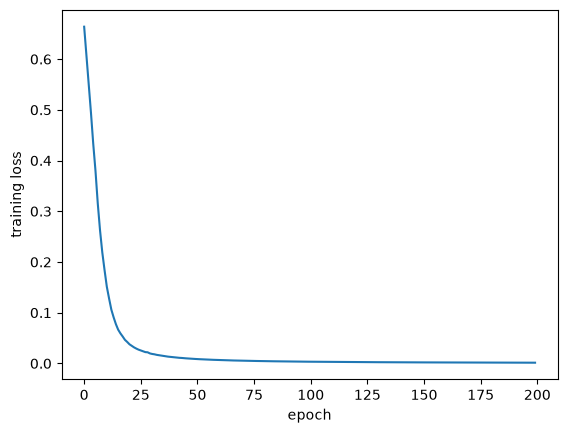

training accuracy on circles: 1.000


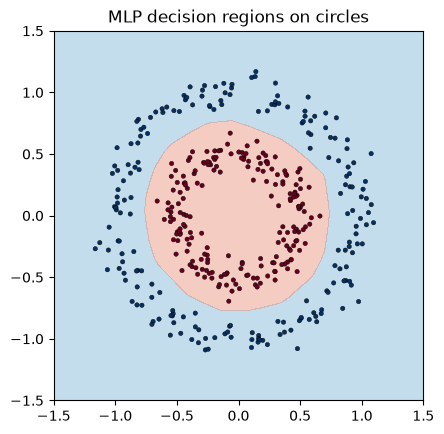

In [11]:
Xc, yc = make_circles(n_samples=400, noise=0.08, factor=0.5, random_state=0)

r = np.random.default_rng(0)
circle_net = Sequential(Linear(2, 32, r), ReLU(), Linear(32, 32, r), ReLU(), Linear(32, 2, r))
hist = train(circle_net, SoftmaxCrossEntropy(), Xc, yc, lr=0.1, epochs=200, batch_size=32)
plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("training loss"); plt.show()
circ_acc = accuracy(circle_net, Xc, yc)
print(f"training accuracy on circles: {circ_acc:.3f}")

g1, g2 = np.meshgrid(np.linspace(-1.5, 1.5, 200), np.linspace(-1.5, 1.5, 200))
Zg = circle_net.forward(np.c_[g1.ravel(), g2.ravel()])
plt.contourf(g1, g2, (Zg[:, 1] - Zg[:, 0]).reshape(g1.shape), levels=[-1e9, 0, 1e9], cmap="RdBu_r", alpha=0.4)
plt.scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="RdBu_r", s=10, edgecolor="k", linewidth=0.3)
plt.gca().set_aspect("equal"); plt.title("MLP decision regions on circles"); plt.show()

In [12]:
# A sanity check of `train` on a tiny problem with a known answer
_r = np.random.default_rng(0)
_net = Sequential(Linear(2, 2, _r))
_h = train(_net, SoftmaxCrossEntropy(), np.array([[1.0, 0.0], [0.0, 1.0]]), np.array([0, 1]),
           lr=0.5, epochs=50, batch_size=2)
assert len(_h) == 50 and _h[-1] < _h[0] and _h[-1] < 0.1
assert circ_acc >= 0.97
print("training OK")

training OK


## Exercise 2.5 — Width and depth on two moons

Use your `train` function to study how **width** and **depth** affect an MLP on the
noisy two-moons data below. For every combination of `depth` in `[1, 2, 3]` hidden
layers and `width` in `[2, 8, 32]` units per layer, build a ReLU MLP, train it with
`lr=0.1`, `epochs=100`, `batch_size=32`, and record its **validation** accuracy.

Store the results in a dictionary `results` mapping `(depth, width)` to the
validation accuracy (a float). Plot or print them, and plot the decision boundary of
a few of the models if you like. Then answer the question below.

In [13]:
Xm, ym = make_moons(n_samples=600, noise=0.25, random_state=1)
Xm_tr, Xm_va, ym_tr, ym_va = train_test_split(Xm, ym, test_size=0.5, random_state=0)

def make_mlp(n_in, n_out, width, depth, rng):
    """ReLU MLP with `depth` hidden layers of `width` units."""
    layers, d = [], n_in
    for _ in range(depth):
        layers += [Linear(d, width, rng), ReLU()]
        d = width
    return Sequential(*layers, Linear(d, n_out, rng))

results = {}
for depth in [1, 2, 3]:
    for width in [2, 8, 32]:
        net = make_mlp(2, 2, width, depth, np.random.default_rng(0))
        train(net, SoftmaxCrossEntropy(), Xm_tr, ym_tr, lr=0.1, epochs=100, batch_size=32)
        results[(depth, width)] = accuracy(net, Xm_va, ym_va)

print("validation accuracy (rows: depth, columns: width)")
print("         " + "".join(f"{w:>8d}" for w in [2, 8, 32]))
for depth in [1, 2, 3]:
    print(f"depth {depth}: " + "".join(f"{results[(depth, w)]:8.3f}" for w in [2, 8, 32]))

validation accuracy (rows: depth, columns: width)
                2       8      32
depth 1:    0.873   0.890   0.930
depth 2:    0.893   0.917   0.933
depth 3:    0.463   0.897   0.940


In [14]:
assert set(results) == {(d, w) for d in [1, 2, 3] for w in [2, 8, 32]}
assert all(0.0 <= v <= 1.0 for v in results.values())
assert max(results.values()) >= 0.9
print("results OK")

results OK


**Question.** What do you observe? Why can a network with width 2 struggle even
when it is deep? Is the best *validation* accuracy obtained by the largest network?
What would you expect if you also looked at the *training* accuracy?

**Solution.** 
Width-2 networks are a bottleneck: every hidden layer maps the data to a 2-D space
through a ReLU, which can only fold/clip the plane, and with only two ReLUs a unit
that dies (negative on all inputs) removes half the representation. Depth does not
help much because information lost in a narrow layer cannot be recovered later, and
optimisation of very narrow deep ReLU nets is fragile. Once the network is wide enough
(8–32 units) the validation accuracy levels off in the low-to-mid 90s, close to the
best achievable for this noise level (a deep width-2 net may even collapse to chance,
as in our run). Gains from going bigger are small and not guaranteed on held-out
data, because the remaining errors come from noise in the overlapping region. The
training accuracy, in contrast, keeps increasing with capacity — large networks start
to fit the noise (overfitting), which is the topic of the regularisation lecture.


## Exercise 2.6 — Digits with an MLP

Train an MLP on the `digits` dataset using your layers and `train` function. Choose
the architecture, learning rate and number of epochs yourself (keep the training
under ~20 seconds). Your network must reach at least **97 %** test accuracy.
Store the trained network in `digits_net`.

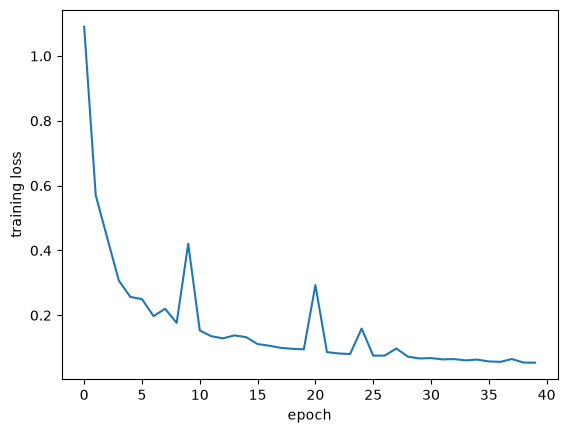

test accuracy: 0.976


In [15]:
digits = load_digits()
Xd = digits.data / 16.0
yd = digits.target
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.25, random_state=0, stratify=yd)

r = np.random.default_rng(0)
digits_net = Sequential(Linear(64, 128, r), ReLU(), Linear(128, 10, r))
hist = train(digits_net, SoftmaxCrossEntropy(), Xd_tr, yd_tr, lr=0.1, epochs=40, batch_size=32)
plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("training loss"); plt.show()
digits_acc = accuracy(digits_net, Xd_te, yd_te)
print(f"test accuracy: {digits_acc:.3f}")

In [16]:
assert digits_acc >= 0.97

**Question.** Softmax regression in Lecture 1 reached about 96–97 % on this data
with only $64\times10+10 = 650$ parameters. How many parameters does your MLP have?
Given the improvement you observed, is it "worth it"? Name one thing a hidden layer
can represent that a linear classifier cannot, in the context of digits.

**Solution.** 
A $64\to128\to10$ network has $64\cdot128 + 128 + 128\cdot10 + 10 = 9\,610$ parameters,
about 15 times more, for a gain of one or two percentage points (i.e. a substantial
*relative* reduction of the error rate). On a small, nearly linearly separable problem
like $8\times8$ digits the gain is modest; on harder data (larger images, more
variation) the gap becomes large. A hidden layer can represent **disjunctions /
invariances**: e.g. "a 7 is either this stroke pattern *or* that slightly shifted
one", or a "4" written open or closed. A linear classifier has one template per
class and has to average such variants into a single blurry prototype; an MLP can
have separate units for each variant and combine them with an OR-like output weight.
